In [ ]:
# Instalar PySpark
!pip install pyspark
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, avg, count, month, expr, rand, round
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Configuración visual para que los gráficos luzcan profesionales
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
# Iniciar Sesión de Spark
spark = SparkSession.builder.appName("OmniStore_Viz").getOrCreate()
print("¡Entorno listo para graficar!")

¡Entorno listo para graficar!


# **GRÁFICO 1:**

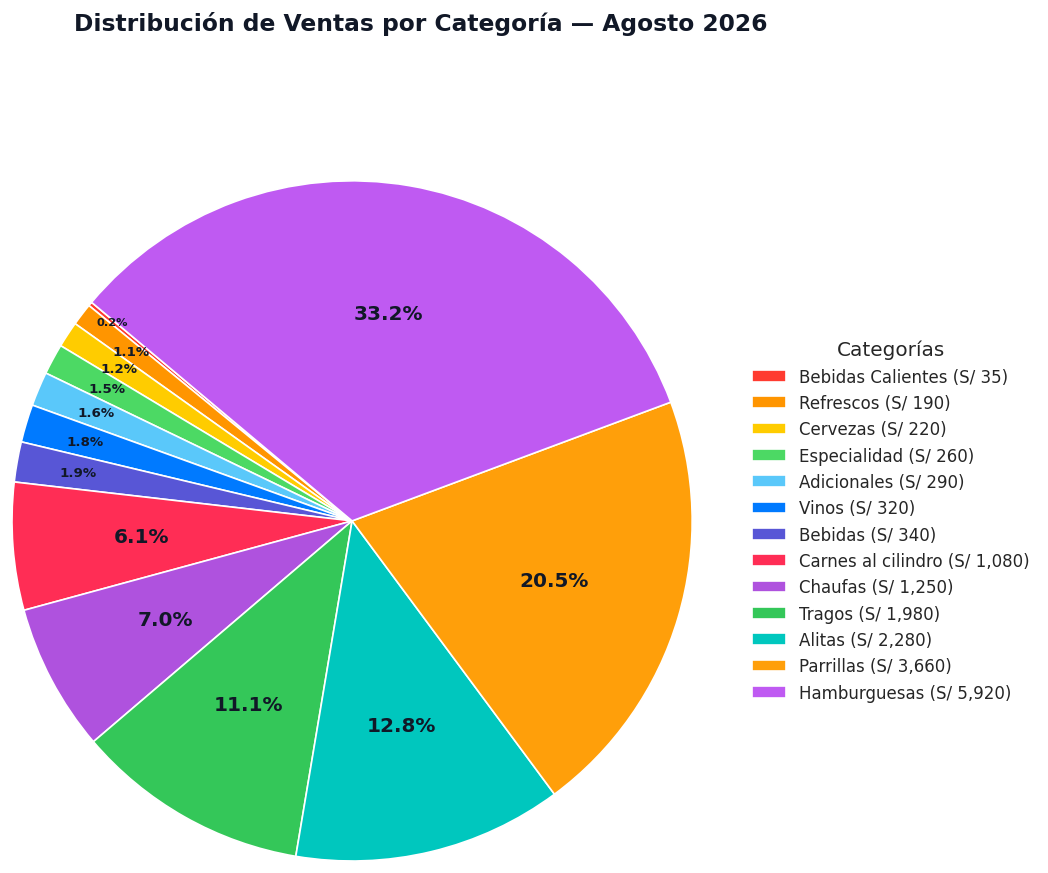

In [47]:
import matplotlib.pyplot as plt

categorias = [
    'Bebidas Calientes', 'Refrescos', 'Cervezas', 'Especialidad',
    'Adicionales', 'Vinos', 'Bebidas', 'Carnes al cilindro',
    'Chaufas', 'Tragos', 'Alitas', 'Parrillas', 'Hamburguesas'
]

ventas = [
    35, 190, 220, 260, 290, 320, 340,
    1080, 1250, 1980, 2280, 3660, 5920
]

# Configuración de la figura
fig, ax = plt.subplots(figsize=(10.5, 8.2), dpi=120)
fig.patch.set_facecolor('#FFFFFF')
ax.set_facecolor('#FFFFFF')

# Paleta de colores más llamativos, vibrantes y contrastados
colores = [
    '#FF3B30', '#FF9500', '#FFCC00', '#4CD964', '#5AC8FA',
    '#007AFF', '#5856D6', '#FF2D55', '#AF52DE', '#34C759',
    '#00C7BE', '#FF9F0A', '#BF5AF2'
]

# Crear el gráfico de pastel (círculo más grande y porcentajes más al centro)
wedges, texts, autotexts = ax.pie(
    ventas,
    labels=None,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    radius=1.28,
    pctdistance=0.62,
    textprops=dict(color='#111827', fontsize=12, fontweight='bold')
)

# Personalizar el estilo de los porcentajes: achicar los pequeños y mantener grandes los principales
for autotext in autotexts:
    valor = float(autotext.get_text().replace('%', ''))
    autotext.set_color('#111827')
    if valor < 1.0:
        autotext.set_fontsize(6.8)
        x, y = autotext.get_position()
        autotext.set_position((x * 1.48, y * 1.48))
    elif valor < 2.5:
        autotext.set_fontsize(8.0)
        x, y = autotext.get_position()
        autotext.set_position((x * 1.32, y * 1.32))
    else:
        autotext.set_fontsize(12)

# Título del gráfico
fig.suptitle(
    'Distribución de Ventas por Categoría — Agosto 2026',
    x=0.06, y=0.96, ha='left', fontsize=14, fontweight='bold', color='#111827'
)

# Añadir la leyenda con los nombres de las categorías y el total de ventas correspondiente
leyendas = [f'{cat} (S/ {monto:,.0f})' for cat, monto in zip(categorias, ventas)]
ax.legend(
    wedges,
    leyendas,
    title="Categorías",
    loc="center left",
    bbox_to_anchor=(1.08, 0.5),
    fontsize=10,
    title_fontsize=12,
    frameon=False
)

plt.tight_layout(rect=[0.0, 0.0, 0.76, 0.93])
plt.show()

# **GRÁFICO 2:**

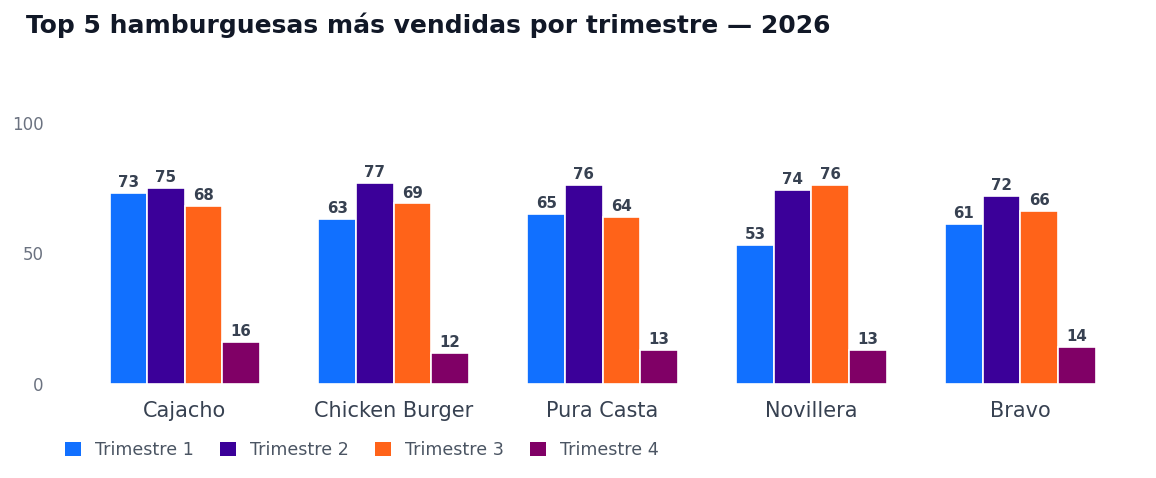

In [53]:
import numpy as np

# Top 5 productos más vendidos
productos = [
    'Cajacho', 'Chicken Burger', 'Pura Casta', 'Novillera', 'Bravo'
]

# Valores exactos de los 4 trimestres para los 5 productos principales
t1 = [73, 63, 65, 53, 61]
t2 = [75, 77, 76, 74, 72]
t3 = [68, 69, 64, 76, 66]
t4 = [16, 12, 13, 13, 14]

x = np.arange(len(productos))
ancho = 0.18

fig, ax = plt.subplots(figsize=(10, 4.8), dpi=120)
fig.patch.set_facecolor('#FFFFFF')
ax.set_facecolor('#FFFFFF')

colores = ['#1170FF', '#3B0099', '#FF6319', '#800066']

b1 = ax.bar(x - 1.5 * ancho, t1, width=ancho, color=colores[0], label='Trimestre 1')
b2 = ax.bar(x - 0.5 * ancho, t2, width=ancho, color=colores[1], label='Trimestre 2')
b3 = ax.bar(x + 0.5 * ancho, t3, width=ancho, color=colores[2], label='Trimestre 3')
b4 = ax.bar(x + 1.5 * ancho, t4, width=ancho, color=colores[3], label='Trimestre 4')

# Mostrar los números encima de los 5 pilares
for grupo in [b1, b2, b3, b4]:
    for barra in grupo:
        altura = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            altura + 1.2,
            f'{altura}',
            ha='center', va='bottom', fontsize=9, color='#374151', fontweight='bold'
        )

fig.suptitle(
    'Top 5 hamburguesas más vendidas por trimestre — 2026',
    x=0.04, y=0.95, ha='left', fontsize=15, fontweight='bold', color='#111827'
)

for borde in ['top', 'right', 'bottom', 'left']:
    ax.spines[borde].set_visible(False)

ax.grid(False)

# Nombres de los productos más grandes en el eje X
ax.set_xticks(x)
ax.set_xticklabels(productos, fontsize=12.5, fontweight='medium', color='#374151')
ax.set_yticks([0, 50, 100])
ax.set_yticklabels(['0', '50', '100'], fontsize=10, color='#6B7280')
ax.set_ylim(0, 105)
ax.tick_params(axis='both', length=0, pad=10)

leyenda = ax.legend(
    loc='upper left', bbox_to_anchor=(-0.01, -0.15),
    ncol=4, frameon=False, handlelength=0.9, handleheight=0.9,
    columnspacing=1.5, fontsize=10.5, labelcolor='#4B5563'
)
for handle in leyenda.legend_handles:
    handle.set_linewidth(0)

plt.tight_layout(rect=[0.01, 0.08, 0.99, 0.90])
plt.show()